# Phase 3: Baseline models — BOD and COD

**Purpose:** establish leakage-safe benchmark performance for BOD and COD, and separate what the calendar alone predicts from what routine chemistry adds, before model development.

### Experiments
- **3.0** Locked features and population, read from `phase2_manifest.json`; folds verified against Phase 0
- **3.1** Naïve lookup baselines — only ones that can actually use their lookup under each protocol
- **3.2** Temporal benchmark suite (Ridge): month-only, season-only, chemistry-only, chemistry + {month, season, cyclic month}
- **3.3** Linear models on the locked features — Ridge, Lasso, ElasticNet
- **3.4** Tree models on the locked features — Random Forest, XGBoost, LightGBM
- **3.5** Consolidated comparison, threshold metrics, paired fold comparison
- **3.6** Secondary protocols and the cross-river duplicate sensitivity check
- **3.7** Figures
- **3.8** Manifest

### Metrics reported for every model
| Metric | What it measures |
|---|---|
| `R2_log_mean` | **Pre-specified primary.** Unweighted mean of per-fold R² (log scale). Under LOSO-River this is *within-held-out-river* skill, with each river weighted equally. |
| `R2_log_wmean` | The same per-fold R², weighted by fold size. |
| `R2_log_pooled`, `MAE_mgL_pooled`, `RMSE_mgL_pooled` | Computed once over all out-of-fold predictions. Pooled MAE and RMSE equal the row-weighted fold values exactly. Pooled R² also credits getting between-river levels right. |
| `*_smear` | mg/L metrics after Duan smearing. See 3.5 for why classification stays unsmeared. |


In [1]:
# Setup. `pip install -e .` from the repository root makes `src` importable (README);
# without it, the repository root (the parent of notebooks/) is added to the path.
try:
    import src  # noqa: F401
except ModuleNotFoundError:
    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path.cwd().resolve().parent))

import sys
import json
import time
from pathlib import Path
from collections import Counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest


from src.config import (
    rel, SEED, PRIMARY_FEATURES, PRIMARY_TARGET, PRIMARY_THRESHOLD,
    RESULTS_DIR, FIGURES_DIR, FOLD_KEYS_PATH,
    MONTH_DUMMY_COLS, CYCLIC_MONTH_COLS, SEASON_COLS,
    RIDGE_ALPHAS, LASSO_GRID, ENET_GRID, RF_GRID, XGB_GRID, LGBM_GRID,
)
from src.data_loading import (
    load_locked_dataset, load_phase2_lock, exclude_flagged_cross_river_duplicates, as_bool,
)
from src.folds import (
    build_loso_river, build_loso_station, build_fc,
    build_stratified_kfold, build_random_splits,
    inner_cv_for_folds, verify_fold_keys,
)
from src.evaluation import (
    evaluate_model, evaluate_model_oof, evaluate_lookup_baseline, summarize_with_pooled,
)
from src.models import (
    GrandMeanBaseline, fit_ridge_cv, fit_lasso_cv, fit_elasticnet_cv,
    fit_random_forest, fit_xgboost, fit_lightgbm,
)

warnings.filterwarnings("ignore", category=FutureWarning)   # library deprecation notices; no effect on results
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

PACKAGE_VERSIONS = {}
for pkg in ["numpy", "pandas", "sklearn", "scipy", "xgboost", "lightgbm"]:
    try:
        PACKAGE_VERSIONS[pkg] = __import__(pkg).__version__
    except ImportError:
        PACKAGE_VERSIONS[pkg] = None
XGBOOST_AVAILABLE = PACKAGE_VERSIONS["xgboost"] is not None
LIGHTGBM_AVAILABLE = PACKAGE_VERSIONS["lightgbm"] is not None
print("Package versions:", PACKAGE_VERSIONS)

OUTPUTS = []          # every file this notebook writes, for the manifest
def out_path(name):
    OUTPUTS.append(name)
    return RESULTS_DIR / name

Package versions: {'numpy': '2.4.2', 'pandas': '3.0.0', 'sklearn': '1.8.0', 'scipy': '1.17.1', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}


## 3.0 Locked features, population and folds

The predictor set and the analysis population are read from `phase2_manifest.json`. The notebook stops if that file is missing or incomplete. `config.PRIMARY_FEATURES` is printed for comparison but not used.

Folds are rebuilt deterministically from the locked dataframe. If Phase 0 has written `fold_keys_by_dataset.json`, every rebuilt fold is checked against it by observation key, and any mismatch stops the notebook.

BOD and COD are modelled in parallel with identical predictors and folds; neither is used to predict the other.

In [3]:
# Load the Phase 2 lock and the locked dataset
p2 = load_phase2_lock()          # raises if missing or incomplete

LOCKED_DATASET = p2["locked_dataset"]
MODEL_FEATURES = list(p2["locked_features"])
CHEMISTRY = list(p2["locked_chemistry_features"])
TEMPORAL = list(p2["locked_temporal_features"])
PCA_BLOCK = p2["locked_pca_block"]

assert [float(a) for a in p2["ridge_alphas"]] == [float(a) for a in RIDGE_ALPHAS], (
    "src/config.py RIDGE_ALPHAS changed since Phase 2 ran; rerun Phase 2 so the "
    "benchmark Ridge fits here are the same models Phase 2 compared."
)

MONTH_DUMMIES = list(MONTH_DUMMY_COLS)       # December is the reference

# Calendar columns are added by src.data_loading.add_calendar_columns.
df = load_locked_dataset(LOCKED_DATASET).reset_index(drop=True)
assert df.index.equals(pd.RangeIndex(len(df))), "Index must be RangeIndex(0, n)."

TARGETS = {"BOD": PRIMARY_TARGET, "COD": "log_COD"}
required = MODEL_FEATURES + CHEMISTRY + MONTH_DUMMIES + SEASON_COLS + CYCLIC_MONTH_COLS + [
    "BOD", "COD", "log_BOD", "log_COD", "River", "Place", "Station_ID", "Year", "Month_num", "Season"]
missing_cols = [c for c in dict.fromkeys(required) if c not in df.columns]
if missing_cols:
    raise KeyError(f"Missing required columns: {missing_cols}")
assert df[MODEL_FEATURES + ["log_BOD", "log_COD"]].notna().all().all(), (
    "Locked predictors or a target contain missing values in the locked population."
)
assert np.allclose(df["log_BOD"], np.log1p(df["BOD"])), "log_BOD != log1p(BOD)"
assert np.allclose(df["log_COD"], np.log1p(df["COD"])), "log_COD != log1p(COD)"
assert set(df["Month_num"].unique()) == set(range(1, 13))

def target_threshold(target_col):
    # Phase 3 reports threshold metrics for BOD (6 mg/L); COD screening is part of the full study.
    return PRIMARY_THRESHOLD if target_col == PRIMARY_TARGET else None

print(f"Locked dataset      : {LOCKED_DATASET}  ({len(df)} rows, {df['River'].nunique()} rivers, "
      f"{df['Station_ID'].nunique()} stations)")
print(f"Locked features     : {MODEL_FEATURES}  (pca_block={PCA_BLOCK})")
print(f"  chemistry         : {CHEMISTRY}")
print(f"  temporal          : {TEMPORAL or 'none'}  (Phase 2 selected: {p2.get('selected_temporal_representation')})")
print(f"config.PRIMARY_FEATURES (not used): {list(PRIMARY_FEATURES)}"
      + ("" if p2.get("config_matches_lock") else "   <-- differs from the lock; update config.py"))

Locked dataset      : DS-3F  (1131 rows, 5 rivers, 30 stations)
Locked features     : ['log_EC', 'pH', 'log1p_DO']  (pca_block=None)
  chemistry         : ['log_EC', 'pH', 'log1p_DO']
  temporal          : none  (Phase 2 selected: None)
config.PRIMARY_FEATURES (not used): ['log_EC', 'pH', 'log1p_DO']


In [4]:
# Build outer folds, validate them, verify against Phase 0, describe their composition
loso_river = build_loso_river(df)
loso_station = build_loso_station(df)
forward_chain = build_fc(df)
stratified_5f = build_stratified_kfold(df)
random_8020 = build_random_splits(df)

ALL_FOLDS = {
    "loso_river": loso_river, "loso_station": loso_station, "forward_chain": forward_chain,
    "stratified_5f": stratified_5f, "random_8020": random_8020,
}

for name, folds in ALL_FOLDS.items():
    for tr, te, label in folds:
        tr, te = pd.Index(tr), pd.Index(te)
        assert tr.isin(df.index).all() and te.isin(df.index).all(), f"{name}/{label}: invalid indices"
        assert tr.intersection(te).empty, f"{name}/{label}: train/test overlap"
    print(f"{name:14s}: {len(folds):2d} folds, test sizes {[len(te) for _, te, _ in folds][:8]}"
          + (" ..." if len(folds) > 8 else ""))

# Verify against the keyed folds frozen by Phase 0 (src.folds.save_fold_keys).
ver = verify_fold_keys(df, LOCKED_DATASET, ALL_FOLDS)
if ver is None:
    fold_verification = "not run (no frozen keys)"
    print(f"WARNING: no frozen keys for {LOCKED_DATASET} in {FOLD_KEYS_PATH}. "
          "Run Phase 0 to freeze keyed folds; continuing unverified.")
else:
    ver.to_csv(out_path("phase3_fold_key_verification.csv"), index=False)
    bad = ver[~ver["matches_frozen"]]
    if len(bad):
        display(bad)
        raise AssertionError("Rebuilt folds differ from the folds frozen in Phase 0 (see table).")
    fold_verification = f"all {len(ver)} folds match Phase 0"
    print(f"Fold verification: {fold_verification}")

# Composition: Forward-Chain is not a purely temporal test when the station network changes.
all_rivers = set(df["River"])
comp = []
for tr, te, label in forward_chain:
    tr_st = set(df.loc[tr, "Station_ID"])
    te_d = df.loc[te]
    unseen = ~te_d["Station_ID"].isin(tr_st)
    comp.append({
        "protocol": "Forward-Chain", "fold": label,
        "test_years": ", ".join(str(y) for y in sorted(te_d["Year"].unique())),
        "n_test": len(te), "pct_of_data": round(100 * len(te) / len(df), 1),
        "rivers_absent_from_test": ", ".join(sorted(all_rivers - set(te_d["River"]))) or "—",
        "n_unseen_stations": int(te_d.loc[unseen, "Station_ID"].nunique()),
        "pct_test_rows_from_unseen_stations": round(100 * unseen.mean(), 1),
    })
for tr, te, label in loso_river:
    comp.append({"protocol": "LOSO-River", "fold": label, "n_test": len(te),
                 "pct_of_data": round(100 * len(te) / len(df), 1)})
fold_composition = pd.DataFrame(comp)
display(fold_composition)
fold_composition.to_csv(out_path("phase3_fold_composition.csv"), index=False)

loso_river    :  5 folds, test sizes [112, 512, 184, 77, 246]
loso_station  : 30 folds, test sizes [32, 40, 20, 20, 68, 21, 68, 46] ...
forward_chain :  4 folds, test sizes [207, 219, 130, 191]
stratified_5f :  5 folds, test sizes [227, 226, 226, 226, 226]
random_8020   : 20 folds, test sizes [227, 227, 227, 227, 227, 227, 227, 227] ...
Fold verification: all 64 folds match Phase 0


,protocol,fold,test_years,n_test,pct_of_data,rivers_absent_from_test,n_unseen_stations,pct_test_rows_from_unseen_stations
0,Forward-Chain,FC-1,2019,207,18.3,—,0.0,0.0
1,Forward-Chain,FC-2,2020,219,19.4,—,0.0,0.0
2,Forward-Chain,FC-3,2021,130,11.5,Tongi Khal,9.0,54.6
3,Forward-Chain,FC-4,2022,191,16.9,Tongi Khal,0.0,0.0
4,LOSO-River,Balu River,NaN,112,9.9,NaN,NaN,NaN
5,LOSO-River,Buriganga,NaN,512,45.3,NaN,NaN,NaN
6,LOSO-River,Shitalakhya,NaN,184,16.3,NaN,NaN,NaN
7,LOSO-River,Tongi Khal,NaN,77,6.8,NaN,NaN,NaN
8,LOSO-River,Turag,NaN,246,21.8,NaN,NaN,NaN


### Run registry

Every evaluation goes through `src.evaluation.evaluate_model_oof`, the same code path as `evaluate_model`, which also returns out-of-fold predictions and per-fold Duan smearing factors. Summaries come from `summarize_with_pooled`. The inner splitter for each outer protocol comes from `src.folds.inner_cv_for_folds`.

In [5]:
RUNS = []   # one record per (target, family, model, protocol)

def record(target, family, model, protocol, fold_df, oof, features=None, grid=None):
    RUNS.append({"target": target, "family": family, "model": model, "protocol": protocol,
                 "features": list(features or []), "grid": grid, "fold_df": fold_df, "oof": oof})

def find_run(target, family, model, protocol):
    hits = [r for r in RUNS if (r["target"], r["family"], r["model"], r["protocol"])
            == (target, family, model, protocol)]
    return hits[0] if hits else None

def summarize_record(r):
    s = summarize_with_pooled(r["fold_df"], r["oof"], label=f"{r['model']} — {r['protocol']}",
                              threshold=target_threshold(TARGETS[r["target"]]))
    s.update(target=r["target"], family=r["family"], model=r["model"], protocol=r["protocol"],
             features=", ".join(r["features"]))
    return s

SUMMARY_COLS = ["target", "family", "model", "protocol", "n_folds", "R2_log_mean", "R2_log_sd",
                "R2_log_wmean", "R2_log_pooled", "MAE_mgL_mean", "MAE_mgL_pooled", "RMSE_mgL_pooled"]

PRIMARY_PROTOCOLS = {"LOSO-River": ("loso_river", loso_river),
                     "Forward-Chain": ("forward_chain", forward_chain)}

def run_protocol(factory, features, pca, d, protocol_name, target_tag, protocols=PRIMARY_PROTOCOLS):
    scheme, folds = protocols[protocol_name]
    inner_cv, inner_group = inner_cv_for_folds(d, folds, scheme)
    tc = TARGETS[target_tag]
    return evaluate_model_oof(factory(features, inner_cv, pca), d, features, tc, folds,
                              threshold=target_threshold(tc), inner_group_col=inner_group)

## 3.1 Naïve lookup baselines — BOD and COD

Each baseline is a hierarchical lookup of training-fold means on the log scale. It tries the most specific level first and falls back level by level. Every test row records which level served it, and the notebook stops if a reported baseline would be the grand mean in disguise.

| Baseline | Levels | Protocols |
|---|---|---|
| Grand Mean *(control)* | grand | LOSO-River, Forward-Chain, LOSO-Station |
| Month climatology | month → grand | LOSO-River, Forward-Chain, LOSO-Station |
| River mean | river → grand | Forward-Chain, LOSO-Station |
| River × Month climatology | river×month → month → grand | Forward-Chain, LOSO-Station |
| Station → River mean | station → river → grand | Forward-Chain |

**Not computed:** river mean under LOSO-River and station mean under LOSO-Station. The held-out group is never in training, so both are the grand mean by construction.

In [6]:
NAIVE_SPECS = {
    # name: (levels, protocols, role)
    "Grand Mean": ([[]], ["LOSO-River", "Forward-Chain", "LOSO-Station"], "control"),
    "Month climatology": ([["Month_num"], []], ["LOSO-River", "Forward-Chain", "LOSO-Station"], "baseline"),
    "River mean": ([["River"], []], ["Forward-Chain", "LOSO-Station"], "baseline"),
    "River × Month climatology": ([["River", "Month_num"], ["Month_num"], []],
                                  ["Forward-Chain", "LOSO-Station"], "baseline"),
    "Station → River mean": ([["Station_ID"], ["River"], []], ["Forward-Chain"], "baseline"),
}
NAIVE_FOLDS = {"LOSO-River": loso_river, "Forward-Chain": forward_chain, "LOSO-Station": loso_station}

coverage_rows = []
for target_tag, target_col in TARGETS.items():
    thr = target_threshold(target_col)
    for name, (levels, protocols, role) in NAIVE_SPECS.items():
        for protocol in protocols:
            fdf, oof = evaluate_lookup_baseline(df, NAIVE_FOLDS[protocol], target_col, levels, thr)
            record(target_tag, "Naive", name, protocol, fdf, oof)
            for _, r in fdf.iterrows():
                coverage_rows.append({"target": target_tag, "baseline": name, "role": role,
                                      "protocol": protocol, "fold": r["fold"], "n": r["n"],
                                      "pct_first_level": r["pct_first_level"],
                                      "pct_grand_mean": r["pct_grand_mean"]})

naive_summary = pd.DataFrame([summarize_record(r) for r in RUNS if r["family"] == "Naive"])
display(naive_summary[SUMMARY_COLS].round(4))
naive_summary.to_csv(out_path("phase3_naive_baselines_summary_bod_cod.csv"), index=False)

,target,family,model,protocol,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_pooled
0,BOD,Naive,Grand Mean,LOSO-River,5,-0.1057,0.0957,-0.0670,-0.0215,10.7804,8.6312,13.6029
1,BOD,Naive,Grand Mean,Forward-Chain,4,-0.1003,0.1532,-0.1142,-0.0621,7.9134,7.9458,12.8094
2,BOD,Naive,Grand Mean,LOSO-Station,30,-0.1627,0.3389,-0.1253,-0.0063,9.2042,8.5881,13.6099
3,BOD,Naive,Month climatology,LOSO-River,5,0.3911,0.1942,0.4494,0.4805,8.1898,6.2896,10.7064
4,BOD,Naive,Month climatology,Forward-Chain,4,0.2510,0.1953,0.2249,0.2825,5.7647,5.8943,9.6784
5,BOD,Naive,Month climatology,LOSO-Station,30,0.4015,0.4949,0.4262,0.5215,6.4172,5.8989,10.3382
6,BOD,Naive,River mean,Forward-Chain,4,-0.0771,0.1575,-0.0935,-0.0415,7.8215,7.8622,12.5141
7,BOD,Naive,River mean,LOSO-Station,30,-0.1560,0.3658,-0.1033,0.0225,9.1525,8.5308,13.1573
8,BOD,Naive,River × Month climatology,Forward-Chain,4,0.2738,0.1998,0.2431,0.2977,5.8739,6.0511,9.6461
9,BOD,Naive,River × Month climatology,LOSO-Station,30,0.4618,0.4044,0.4975,0.5972,5.7261,5.1446,8.6312


In [7]:
# 3.1b — coverage audit: no reported baseline may be the grand mean in disguise
coverage = pd.DataFrame(coverage_rows)
coverage.to_csv(out_path("phase3_naive_coverage_audit.csv"), index=False)
display(
    coverage.groupby(["target", "baseline", "protocol"])[["pct_first_level", "pct_grand_mean"]]
    .agg(["min", "mean", "max"]).round(3)
)

base = coverage[coverage["role"] == "baseline"]
worst_fold = base.groupby(["target", "baseline", "protocol"])["pct_grand_mean"].max()
assert (worst_fold < 1.0).all(), (
    f"Baselines that fell back to the grand mean for every row of some fold:\n{worst_fold[worst_fold >= 1.0]}"
)
month = coverage[coverage["baseline"] == "Month climatology"]
assert (month["pct_first_level"] == 1.0).all(), (
    "Month climatology fell back for some rows — check the Month_num dtype and coverage."
)

# The lookup grand mean must equal the project's GrandMeanBaseline through evaluate_model.
for target_tag, target_col in TARGETS.items():
    for protocol in ["LOSO-River", "Forward-Chain"]:
        ref = evaluate_model(GrandMeanBaseline(), df, MODEL_FEATURES, target_col, NAIVE_FOLDS[protocol],
                             threshold=target_threshold(target_col))
        mine = find_run(target_tag, "Naive", "Grand Mean", protocol)["fold_df"]
        assert np.allclose(ref["R2_log"].to_numpy(), mine["R2_log"].to_numpy(), atol=1e-12)
print("Coverage audit passed: no baseline is 100% grand-mean fallback; month climatology fully covered;")
print("lookup grand mean == GrandMeanBaseline via evaluate_model.")

pct_first_level             pct_grand_mean          
                                                           min   mean  max            min mean  max
target baseline                  protocol                                                          
BOD    Grand Mean                Forward-Chain           1.000  1.000  1.0            1.0  1.0  1.0
                                 LOSO-River              1.000  1.000  1.0            1.0  1.0  1.0
                                 LOSO-Station            1.000  1.000  1.0            1.0  1.0  1.0
       Month climatology         Forward-Chain           1.000  1.000  1.0            0.0  0.0  0.0
                                 LOSO-River              1.000  1.000  1.0            0.0  0.0  0.0
                                 LOSO-Station            1.000  1.000  1.0            0.0  0.0  0.0
       River mean                Forward-Chain           1.000  1.000  1.0            0.0  0.0  0.0
                                 LOSO-Station            1.000  1.000  1.0            0.0  0.0  0.0
       River × Month climatology Forward-Chain           0.971  0.993  1.0            0.0  0.0  0.0
                                 LOSO-Station            1.000  1.000  1.0            0.0  0.0  0.0
       Station → River mean      Forward-Chain           0.454  0.863  1.0            0.0  0.0  0.0
COD    Grand Mean                Forward-Chain           1.000  1.000  1.0            1.0  1.0  1.0
                                 LOSO-River              1.000  1.000  1.0            1.0  1.0  1.0
                                 LOSO-Station            1.000  1.000  1.0            1.0  1.0  1.0
       Month climatology         Forward-Chain           1.000  1.000  1.0            0.0  0.0  0.0
                                 LOSO-River              1.000  1.000  1.0            0.0  0.0  0.0
                                 LOSO-Station            1.000  1.000  1.0            0.0  0.0  0.0
       River mean                Forward-Chain           1.000  1.000  1.0            0.0  0.0  0.0
                                 LOSO-Station            1.000  1.000  1.0            0.0  0.0  0.0
       River × Month climatology Forward-Chain           0.971  0.993  1.0            0.0  0.0  0.0
                                 LOSO-Station            1.000  1.000  1.0            0.0  0.0  0.0
       Station → River mean      Forward-Chain           0.454  0.863  1.0            0.0  0.0  0.0

Coverage audit passed: no baseline is 100% grand-mean fallback; month climatology fully covered;
lookup grand mean == GrandMeanBaseline via evaluate_model.


## 3.2 Temporal benchmark suite — BOD and COD

Ridge, identical folds, on the locked population. The specification equal to the locked features is marked, so the primary model appears in this table.

Month-only and season-only are **benchmarks**, not chemistry surrogates. The per-fold tables matter more than the means. Chemistry can beat the calendar on average while losing to it on a particular river, and those two findings call for different wording in the manuscript.

In [8]:
TEMPORAL_SPECS = {
    "Month-only": MONTH_DUMMIES,
    "Season-only": ["IsDry"],
    "Chemistry-only": CHEMISTRY,
    "Chemistry + Month": CHEMISTRY + MONTH_DUMMIES,
    "Chemistry + Season": CHEMISTRY + ["IsDry"],
    "Chemistry + Cyclic Month": CHEMISTRY + list(CYCLIC_MONTH_COLS),
}
LOCKED_SPEC = next((k for k, v in TEMPORAL_SPECS.items() if v == MODEL_FEATURES), None)
assert LOCKED_SPEC is not None, f"Locked features {MODEL_FEATURES} match no benchmark spec."
print(f"Locked features correspond to benchmark spec: '{LOCKED_SPEC}'")

def pca_for(features):
    if PCA_BLOCK and all(c in features for c in ("log_EC", "log_TDS")):
        return PCA_BLOCK
    return None

ridge_factory = lambda f, cv, pca: fit_ridge_cv(f, cv, pca_block=pca)     # config RIDGE_ALPHAS

for target_tag in TARGETS:
    for spec, feats in TEMPORAL_SPECS.items():
        for protocol in ["LOSO-River", "Forward-Chain"]:
            fdf, oof = run_protocol(ridge_factory, feats, pca_for(feats), df, protocol, target_tag)
            record(target_tag, "Temporal benchmark (Ridge)", spec, protocol, fdf, oof,
                   features=feats, grid={"est__alpha": RIDGE_ALPHAS})

tb_runs = [r for r in RUNS if r["family"] == "Temporal benchmark (Ridge)"]
tb_summary = pd.DataFrame([summarize_record(r) for r in tb_runs])
tb_summary["is_locked_spec"] = tb_summary["model"].eq(LOCKED_SPEC)
display(tb_summary[SUMMARY_COLS + ["is_locked_spec"]].round(4))
tb_summary.to_csv(out_path("phase3_temporal_benchmark_summary_bod_cod.csv"), index=False)
pd.concat([r["fold_df"].assign(target=r["target"], feature_set=r["model"], protocol=r["protocol"])
           for r in tb_runs], ignore_index=True).to_csv(
    out_path("phase3_temporal_benchmark_fold_results_bod_cod.csv"), index=False)

Locked features correspond to benchmark spec: 'Chemistry-only'


,target,family,model,protocol,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_pooled,is_locked_spec
0,BOD,Temporal benchmark (Ridge),Month-only,LOSO-River,5,0.3903,0.1892,0.4545,0.4828,8.2337,6.2037,10.7343,False
1,BOD,Temporal benchmark (Ridge),Month-only,Forward-Chain,4,0.3551,0.1482,0.3374,0.3824,5.8383,5.9872,10.2680,False
2,BOD,Temporal benchmark (Ridge),Season-only,LOSO-River,5,0.1720,0.1337,0.2389,0.2682,9.5870,7.4365,12.1024,False
3,BOD,Temporal benchmark (Ridge),Season-only,Forward-Chain,4,0.1838,0.1125,0.1725,0.2182,6.7664,6.8274,11.2040,False
4,BOD,Temporal benchmark (Ridge),Chemistry-only,LOSO-River,5,0.5331,0.0907,0.4973,0.5330,7.4654,6.1259,10.0560,True
5,BOD,Temporal benchmark (Ridge),Chemistry-only,Forward-Chain,4,0.4080,0.2041,0.3896,0.4314,5.4253,5.5068,9.1565,True
6,BOD,Temporal benchmark (Ridge),Chemistry + Month,LOSO-River,5,0.5263,0.0562,0.5142,0.5463,7.5315,6.0373,10.1274,False
7,BOD,Temporal benchmark (Ridge),Chemistry + Month,Forward-Chain,4,0.4295,0.1854,0.4072,0.4502,5.2347,5.3737,9.1260,False
8,BOD,Temporal benchmark (Ridge),Chemistry + Season,LOSO-River,5,0.5285,0.0886,0.4959,0.5308,7.4990,6.1386,10.0974,False
9,BOD,Temporal benchmark (Ridge),Chemistry + Season,Forward-Chain,4,0.4317,0.1749,0.4166,0.4556,5.4101,5.5032,9.2824,False


In [9]:
# 3.2b — per-fold tables and the chemistry-over-calendar increment
per_fold_tables, increment_rows = [], []
for target_tag in TARGETS:
    for protocol in ["LOSO-River", "Forward-Chain"]:
        runs = [r for r in tb_runs if r["target"] == target_tag and r["protocol"] == protocol]
        long = pd.concat([r["fold_df"].assign(spec=r["model"]) for r in runs], ignore_index=True)
        piv = long.pivot(index="fold", columns="spec", values="R2_log")[list(TEMPORAL_SPECS)]
        n = long.groupby("fold")["n"].first().reindex(piv.index)
        pooled = {r["model"]: summarize_record(r)["R2_log_pooled"] for r in runs}
        table = piv.copy()
        table.insert(0, "n", n)
        table.loc["mean (pre-specified)"] = [np.nan] + list(piv.mean())
        table.loc["mean (n-weighted)"] = [np.nan] + list(piv.mul(n, axis=0).sum() / n.sum())
        table.loc["pooled OOF R²"] = [np.nan] + [pooled[c] for c in piv.columns]
        print(f"\n{target_tag} — {protocol}: per-fold R² (log scale); locked spec = '{LOCKED_SPEC}'")
        display(table.round(3))
        per_fold_tables.append(table.assign(target=target_tag, protocol=protocol))

        chem, mon = piv["Chemistry-only"], piv["Month-only"]
        month_wins = list(piv.index[mon > chem])
        increment_rows.append({
            "target": target_tag, "protocol": protocol,
            "chem_minus_month_unweighted": float((chem - mon).mean()),
            "chem_minus_month_nweighted": float(((chem - mon) * n).sum() / n.sum()),
            "chem_minus_month_pooled": pooled["Chemistry-only"] - pooled["Month-only"],
            "folds_month_only_beats_chemistry": ", ".join(map(str, month_wins)) or "—",
            "locked_minus_chem_unweighted": float((piv[LOCKED_SPEC] - chem).mean()),
        })

pd.concat(per_fold_tables).to_csv(out_path("phase3_temporal_per_fold_r2.csv"))
chem_vs_month = pd.DataFrame(increment_rows)
display(chem_vs_month.round(4))
chem_vs_month.to_csv(out_path("phase3_chemistry_vs_month_increment.csv"), index=False)


BOD — LOSO-River: per-fold R² (log scale); locked spec = 'Chemistry-only'


spec,n,Month-only,Season-only,Chemistry-only,Chemistry + Month,Chemistry + Season,Chemistry + Cyclic Month
fold,,,,,,,
Balu River,112.0,0.283,0.060,0.470,0.472,0.467,0.480
Buriganga,512.0,0.555,0.329,0.409,0.467,0.409,0.449
Shitalakhya,184.0,0.130,0.066,0.626,0.541,0.628,0.536
Tongi Khal,77.0,0.401,0.100,0.593,0.552,0.571,0.558
Turag,246.0,0.582,0.305,0.568,0.599,0.569,0.622
mean (pre-specified),NaN,0.390,0.172,0.533,0.526,0.529,0.529
mean (n-weighted),NaN,0.454,0.239,0.497,0.514,0.496,0.511
pooled OOF R²,NaN,0.483,0.268,0.533,0.546,0.531,0.547



BOD — Forward-Chain: per-fold R² (log scale); locked spec = 'Chemistry-only'


spec,n,Month-only,Season-only,Chemistry-only,Chemistry + Month,Chemistry + Season,Chemistry + Cyclic Month
fold,,,,,,,
FC-1,207.0,0.433,0.270,0.576,0.524,0.586,0.533
FC-2,219.0,0.204,0.052,0.136,0.193,0.208,0.213
FC-3,130.0,0.523,0.285,0.553,0.619,0.555,0.622
FC-4,191.0,0.260,0.129,0.368,0.382,0.378,0.392
mean (pre-specified),NaN,0.355,0.184,0.408,0.430,0.432,0.440
mean (n-weighted),NaN,0.337,0.173,0.390,0.407,0.417,0.419
pooled OOF R²,NaN,0.382,0.218,0.431,0.450,0.456,0.461



COD — LOSO-River: per-fold R² (log scale); locked spec = 'Chemistry-only'


spec,n,Month-only,Season-only,Chemistry-only,Chemistry + Month,Chemistry + Season,Chemistry + Cyclic Month
fold,,,,,,,
Balu River,112.0,0.317,0.065,0.476,0.496,0.476,0.492
Buriganga,512.0,0.475,0.223,0.314,0.311,0.307,0.359
Shitalakhya,184.0,-0.159,-0.155,0.454,0.279,0.453,0.298
Tongi Khal,77.0,0.255,-0.035,0.535,0.469,0.551,0.470
Turag,246.0,0.554,0.255,0.541,0.576,0.541,0.588
mean (pre-specified),NaN,0.288,0.070,0.464,0.426,0.466,0.441
mean (n-weighted),NaN,0.358,0.135,0.417,0.393,0.415,0.419
pooled OOF R²,NaN,0.408,0.187,0.460,0.442,0.459,0.465



COD — Forward-Chain: per-fold R² (log scale); locked spec = 'Chemistry-only'


spec,n,Month-only,Season-only,Chemistry-only,Chemistry + Month,Chemistry + Season,Chemistry + Cyclic Month
fold,,,,,,,
FC-1,207.0,0.446,0.180,0.543,0.549,0.543,0.551
FC-2,219.0,0.319,0.190,0.314,0.320,0.304,0.343
FC-3,130.0,0.263,0.004,0.259,0.303,0.247,0.366
FC-4,191.0,-0.012,0.063,0.118,0.147,0.115,0.132
mean (pre-specified),NaN,0.254,0.109,0.308,0.330,0.302,0.348
mean (n-weighted),NaN,0.260,0.122,0.317,0.336,0.312,0.351
pooled OOF R²,NaN,0.306,0.156,0.358,0.376,0.352,0.392


,target,protocol,chem_minus_month_unweighted,chem_minus_month_nweighted,chem_minus_month_pooled,folds_month_only_beats_chemistry,locked_minus_chem_unweighted
0,BOD,LOSO-River,0.1427,0.0429,0.0502,"Buriganga, Turag",0.0
1,BOD,Forward-Chain,0.0529,0.0521,0.0490,FC-2,0.0
2,COD,LOSO-River,0.1756,0.0589,0.0519,"Buriganga, Turag",0.0
3,COD,Forward-Chain,0.0542,0.0577,0.0519,"FC-2, FC-3",0.0


## 3.3 Linear models — Ridge, Lasso, ElasticNet

Each tuned model is `GridSearchCV` around the complete preprocessing + estimator pipeline (`src.models.tune`), with an inner splitter that mirrors the outer protocol.

**Grids** come from `src/config.py` and extend beyond the values selected in practice (`LASSO_GRID` uses lasso-scale alphas). The edge check after 3.4 lists any parameter chosen at a grid edge.

In [10]:
# Hyperparameter grids: src/config.py (recorded in the manifest).
MODEL_GRIDS = {
    "Ridge": {"est__alpha": list(RIDGE_ALPHAS)},
    "Lasso": LASSO_GRID,
    "ElasticNet": ENET_GRID,
    "Random Forest": RF_GRID,
    "XGBoost": XGB_GRID,
    "LightGBM": LGBM_GRID,
}
# Each factory uses its config grid by default.
FACTORIES = {
    "Ridge": lambda f, cv, pca: fit_ridge_cv(f, cv, pca_block=pca),
    "Lasso": lambda f, cv, pca: fit_lasso_cv(f, cv, pca_block=pca),
    "ElasticNet": lambda f, cv, pca: fit_elasticnet_cv(f, cv, pca_block=pca),
    "Random Forest": lambda f, cv, pca: fit_random_forest(f, cv, pca_block=pca),
    "XGBoost": lambda f, cv, pca: fit_xgboost(f, cv, pca_block=pca),
    "LightGBM": lambda f, cv, pca: fit_lightgbm(f, cv, pca_block=pca),
}
for name, grid in MODEL_GRIDS.items():
    n = int(np.prod([len(v) for v in grid.values()]))
    print(f"{name:13s} {n:4d} combinations  {grid}")

Ridge           10 combinations  {'est__alpha': [0.01, 0.1, 1.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0, 10000.0]}
Lasso            9 combinations  {'est__alpha': [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]}
ElasticNet      35 combinations  {'est__alpha': [0.0001, 0.001, 0.01, 0.03, 0.1, 0.3, 1.0], 'est__l1_ratio': [0.1, 0.25, 0.5, 0.75, 0.9]}
Random Forest   50 combinations  {'est__n_estimators': [300], 'est__max_depth': [2, 3, 5, 10, None], 'est__min_samples_leaf': [5, 10, 20, 40, 80], 'est__max_features': [1.0, 0.5]}
XGBoost        108 combinations  {'est__learning_rate': [0.02, 0.05, 0.1], 'est__max_depth': [1, 2, 3, 5], 'est__n_estimators': [100, 300, 600], 'est__reg_lambda': [1, 10, 100]}
LightGBM       108 combinations  {'est__learning_rate': [0.02, 0.05, 0.1], 'est__max_depth': [1, 2, 3, 5], 'est__n_estimators': [100, 300, 600], 'est__reg_lambda': [1, 10, 100]}


In [11]:
# 3.3 — linear models on the locked features
for target_tag in TARGETS:
    for name in ["Ridge", "Lasso", "ElasticNet"]:
        for protocol in ["LOSO-River", "Forward-Chain"]:
            t0 = time.time()
            fdf, oof = run_protocol(FACTORIES[name], MODEL_FEATURES, PCA_BLOCK, df, protocol, target_tag)
            record(target_tag, "Linear", name, protocol, fdf, oof, MODEL_FEATURES, MODEL_GRIDS[name])
            print(f"{name:10s} {target_tag} {protocol:13s} {time.time() - t0:5.1f}s")

# Consistency: Linear Ridge on the locked features is the same model as the locked benchmark spec.
for target_tag in TARGETS:
    for protocol in ["LOSO-River", "Forward-Chain"]:
        a = find_run(target_tag, "Linear", "Ridge", protocol)["fold_df"]["R2_log"].to_numpy()
        b = find_run(target_tag, "Temporal benchmark (Ridge)", LOCKED_SPEC, protocol)["fold_df"]["R2_log"].to_numpy()
        assert np.allclose(a, b, atol=1e-12), "Linear Ridge and the locked benchmark spec disagree."

linear_summary = pd.DataFrame([summarize_record(r) for r in RUNS if r["family"] == "Linear"])
display(linear_summary[SUMMARY_COLS].round(4))
linear_summary.to_csv(out_path("phase3_linear_models_summary_bod_cod.csv"), index=False)

Ridge      BOD LOSO-River      0.3s
Ridge      BOD Forward-Chain   0.1s
Lasso      BOD LOSO-River      0.3s
Lasso      BOD Forward-Chain   0.2s
ElasticNet BOD LOSO-River      0.8s
ElasticNet BOD Forward-Chain   0.4s
Ridge      COD LOSO-River      0.3s
Ridge      COD Forward-Chain   0.2s
Lasso      COD LOSO-River      0.3s
Lasso      COD Forward-Chain   0.1s
ElasticNet COD LOSO-River      0.8s
ElasticNet COD Forward-Chain   0.3s


,target,family,model,protocol,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_pooled
0,BOD,Linear,Ridge,LOSO-River,5,0.5331,0.0907,0.4973,0.5330,7.4654,6.1259,10.0560
1,BOD,Linear,Ridge,Forward-Chain,4,0.4080,0.2041,0.3896,0.4314,5.4253,5.5068,9.1565
2,BOD,Linear,Lasso,LOSO-River,5,0.5372,0.0909,0.4990,0.5352,7.3509,6.0551,9.8867
3,BOD,Linear,Lasso,Forward-Chain,4,0.3720,0.1427,0.3674,0.3987,5.8380,5.8424,9.7223
4,BOD,Linear,ElasticNet,LOSO-River,5,0.5343,0.0925,0.4978,0.5338,7.4216,6.0927,9.9817
5,BOD,Linear,ElasticNet,Forward-Chain,4,0.4153,0.1633,0.4037,0.4393,5.6342,5.6919,9.5432
6,COD,Linear,Ridge,LOSO-River,5,0.4638,0.0917,0.4171,0.4602,25.3218,21.2715,34.8700
7,COD,Linear,Ridge,Forward-Chain,4,0.3082,0.1771,0.3175,0.3577,20.0579,20.4010,33.6202
8,COD,Linear,Lasso,LOSO-River,5,0.4664,0.0929,0.4193,0.4625,25.1828,21.1478,34.5876
9,COD,Linear,Lasso,Forward-Chain,4,0.3194,0.1489,0.3293,0.3651,20.1025,20.4753,33.8694


## 3.4 Tree-based baselines — BOD and COD

Same locked features, folds and nesting rule as 3.3. Missing optional packages are recorded rather than aborting the notebook.

Runtime is dominated by the boosting grids (108 combinations each with the config grids), roughly 6,500 fits per boosting model across both targets and both protocols.

In [12]:
tree_models = ["Random Forest"]
tree_models += ["XGBoost"] if XGBOOST_AVAILABLE else []
tree_models += ["LightGBM"] if LIGHTGBM_AVAILABLE else []

for target_tag in TARGETS:
    for name in tree_models:
        for protocol in ["LOSO-River", "Forward-Chain"]:
            t0 = time.time()
            fdf, oof = run_protocol(FACTORIES[name], MODEL_FEATURES, PCA_BLOCK, df, protocol, target_tag)
            record(target_tag, "Tree", name, protocol, fdf, oof, MODEL_FEATURES, MODEL_GRIDS[name])
            print(f"{name:13s} {target_tag} {protocol:13s} {time.time() - t0:6.1f}s")

tree_summary = pd.DataFrame([summarize_record(r) for r in RUNS if r["family"] == "Tree"])
display(tree_summary[SUMMARY_COLS].round(4))
tree_summary.to_csv(out_path("phase3_tree_models_summary_bod_cod.csv"), index=False)

dependency_status = pd.DataFrame([
    {"model": "Random Forest", "package": "scikit-learn", "version": PACKAGE_VERSIONS["sklearn"], "status": "RUN"},
    {"model": "XGBoost", "package": "xgboost", "version": PACKAGE_VERSIONS["xgboost"],
     "status": "RUN" if XGBOOST_AVAILABLE else "SKIPPED — package not installed"},
    {"model": "LightGBM", "package": "lightgbm", "version": PACKAGE_VERSIONS["lightgbm"],
     "status": "RUN" if LIGHTGBM_AVAILABLE else "SKIPPED — package not installed"},
])
display(dependency_status)
dependency_status.to_csv(out_path("phase3_tree_dependency_status.csv"), index=False)

Random Forest BOD LOSO-River     125.9s
Random Forest BOD Forward-Chain   48.8s
XGBoost       BOD LOSO-River     175.1s
XGBoost       BOD Forward-Chain   66.7s
LightGBM      BOD LOSO-River      40.1s
LightGBM      BOD Forward-Chain    9.8s
Random Forest COD LOSO-River     146.9s
Random Forest COD Forward-Chain   48.8s
XGBoost       COD LOSO-River     143.0s
XGBoost       COD Forward-Chain   66.4s
LightGBM      COD LOSO-River      49.6s
LightGBM      COD Forward-Chain   15.7s


,target,family,model,protocol,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_pooled
0,BOD,Tree,Random Forest,LOSO-River,5,0.5070,0.1160,0.4586,0.5010,7.5608,6.3486,10.3011
1,BOD,Tree,Random Forest,Forward-Chain,4,0.3871,0.1700,0.3673,0.4098,5.5687,5.6811,9.6784
2,BOD,Tree,XGBoost,LOSO-River,5,0.5145,0.1157,0.4584,0.5021,7.4567,6.3452,10.1214
3,BOD,Tree,XGBoost,Forward-Chain,4,0.3856,0.1473,0.3702,0.4071,5.7197,5.8067,9.8633
4,BOD,Tree,LightGBM,LOSO-River,5,0.5124,0.1223,0.4528,0.4984,7.4974,6.4275,10.1765
5,BOD,Tree,LightGBM,Forward-Chain,4,0.3918,0.1613,0.3725,0.4129,5.6484,5.7535,9.7274
6,COD,Tree,Random Forest,LOSO-River,5,0.4335,0.1113,0.3771,0.4243,25.5712,21.6640,35.4292
7,COD,Tree,Random Forest,Forward-Chain,4,0.3287,0.1381,0.3379,0.3730,20.5695,20.9548,35.0282
8,COD,Tree,XGBoost,LOSO-River,5,0.4354,0.1063,0.3771,0.4236,25.7577,22.0040,35.2111
9,COD,Tree,XGBoost,Forward-Chain,4,0.3115,0.1287,0.3215,0.3560,20.3493,20.7250,33.8943


,model,package,version,status
0,Random Forest,scikit-learn,1.8.0,RUN
1,XGBoost,xgboost,3.4.1,RUN
2,LightGBM,lightgbm,4.7.0,RUN


In [13]:
# 3.4b — hyperparameter edge audit (Linear and Tree families)
audit_rows = []
for r in RUNS:
    if r["family"] not in ("Linear", "Tree") or not r["grid"]:
        continue
    chosen_all = list(r["fold_df"]["best_params_dict"])
    for param, values in r["grid"].items():
        values = list(values)
        if len(values) < 2:
            continue
        numeric = [v for v in values if v is not None]
        lo, hi = min(numeric), max(numeric)
        upper_is_none = any(v is None for v in values)      # e.g. max_depth=None = unlimited
        chosen = [bp.get(param) for bp in chosen_all]
        audit_rows.append({
            "target": r["target"], "model": r["model"], "protocol": r["protocol"], "param": param,
            "grid": str(values), "n_folds": len(chosen),
            "n_at_lower_edge": sum(c is not None and c == lo for c in chosen),
            "n_at_upper_edge": sum((c is None) if upper_is_none else (c == hi) for c in chosen),
            "chosen": str(dict(Counter(map(str, chosen)))),
        })
edge_audit = pd.DataFrame(audit_rows)
edge_audit["pct_on_edge"] = 100 * (edge_audit["n_at_lower_edge"] + edge_audit["n_at_upper_edge"]) / edge_audit["n_folds"]
display(edge_audit.sort_values("pct_on_edge", ascending=False).head(20))
edge_audit.to_csv(out_path("phase3_hyperparameter_edge_audit.csv"), index=False)
print("Parameters on a grid edge in every fold:")
display(edge_audit[edge_audit["pct_on_edge"] == 100][["target", "model", "protocol", "param", "chosen"]])

,target,model,protocol,param,grid,n_folds,n_at_lower_edge,n_at_upper_edge,chosen,pct_on_edge
5,BOD,ElasticNet,LOSO-River,est__l1_ratio,"[0.1, 0.25, 0.5, 0.75, 0.9]",5,4,1,"{'0.1': 4, '0.9': 1}",100.0
26,BOD,XGBoost,Forward-Chain,est__learning_rate,"[0.02, 0.05, 0.1]",4,4,0,{'0.02': 4},100.0
18,BOD,Random Forest,LOSO-River,est__max_features,"[1.0, 0.5]",5,4,1,"{'0.5': 4, '1.0': 1}",100.0
13,COD,ElasticNet,LOSO-River,est__l1_ratio,"[0.1, 0.25, 0.5, 0.75, 0.9]",5,4,1,"{'0.1': 4, '0.9': 1}",100.0
21,BOD,Random Forest,Forward-Chain,est__max_features,"[1.0, 0.5]",4,4,0,{'0.5': 4},100.0
53,COD,LightGBM,LOSO-River,est__max_depth,"[1, 2, 3, 5]",5,5,0,{'1': 5},100.0
45,COD,XGBoost,LOSO-River,est__max_depth,"[1, 2, 3, 5]",5,5,0,{'1': 5},100.0
43,COD,Random Forest,Forward-Chain,est__max_features,"[1.0, 0.5]",4,4,0,{'0.5': 4},100.0
36,BOD,LightGBM,Forward-Chain,est__n_estimators,"[100, 300, 600]",4,4,0,{'100': 4},100.0
40,COD,Random Forest,LOSO-River,est__max_features,"[1.0, 0.5]",5,5,0,{'0.5': 5},100.0


Parameters on a grid edge in every fold:


,target,model,protocol,param,chosen
5,BOD,ElasticNet,LOSO-River,est__l1_ratio,"{'0.1': 4, '0.9': 1}"
13,COD,ElasticNet,LOSO-River,est__l1_ratio,"{'0.1': 4, '0.9': 1}"
18,BOD,Random Forest,LOSO-River,est__max_features,"{'0.5': 4, '1.0': 1}"
21,BOD,Random Forest,Forward-Chain,est__max_features,{'0.5': 4}
26,BOD,XGBoost,Forward-Chain,est__learning_rate,{'0.02': 4}
28,BOD,XGBoost,Forward-Chain,est__n_estimators,{'100': 4}
34,BOD,LightGBM,Forward-Chain,est__learning_rate,{'0.02': 4}
36,BOD,LightGBM,Forward-Chain,est__n_estimators,{'100': 4}
40,COD,Random Forest,LOSO-River,est__max_features,{'0.5': 5}
43,COD,Random Forest,Forward-Chain,est__max_features,{'0.5': 4}


## 3.5 Consolidated comparison — BOD and COD

The comparison combines the naïve baselines, the temporal benchmarks, and the linear and tree models on the two primary tracks. Every model is also compared against two references: the grand mean, and the calendar (month climatology and month-only Ridge).

**Threshold metrics (BOD, 6 mg/L).** When most samples exceed the threshold (see `prevalence`), a rule that always predicts "exceeds" already scores a high F1 (`F1_always_exceed`). Lead with balanced accuracy, MCC and κ. Classification uses the unsmeared back-transform: `expm1(ŷ)` estimates the conditional median, and P(BOD > 6) > 0.5 exactly when the median exceeds 6.

**Paired fold comparison.** With 5 LOSO-River folds, the smallest attainable two-sided sign-test p-value is 0.0625, and with 4 Forward-Chain folds it is 0.125. No between-model difference can be declared significant from fold counts alone, so describe differences rather than rank models.

In [14]:
# 3.5a — consolidated table with deltas against the grand mean and the calendar
primary = [r for r in RUNS if r["protocol"] in ("LOSO-River", "Forward-Chain")]
comparison = pd.DataFrame([summarize_record(r) for r in primary])

def ref_value(target, protocol, family, model):
    hit = comparison[(comparison["target"] == target) & (comparison["protocol"] == protocol)
                     & (comparison["family"] == family) & (comparison["model"] == model)]
    return float(hit["R2_log_mean"].iloc[0]) if len(hit) else np.nan

for col, fam, mod in [("dR2_vs_grand_mean", "Naive", "Grand Mean"),
                      ("dR2_vs_month_climatology", "Naive", "Month climatology"),
                      ("dR2_vs_month_only_ridge", "Temporal benchmark (Ridge)", "Month-only")]:
    comparison[col] = [
        row["R2_log_mean"] - ref_value(row["target"], row["protocol"], fam, mod)
        for _, row in comparison.iterrows()
    ]

show = SUMMARY_COLS + ["dR2_vs_grand_mean", "dR2_vs_month_climatology", "dR2_vs_month_only_ridge",
                       "bias_mgL_pooled", "bias_mgL_pooled_smear", "RMSE_mgL_pooled_smear"]
display(comparison.sort_values(["target", "protocol", "family", "model"])[show].round(4))
comparison.to_csv(out_path("phase3_baseline_model_comparison_bod_cod.csv"), index=False)

# Long-format fold results and out-of-fold predictions for every run
pd.concat([r["fold_df"].assign(target=r["target"], family=r["family"], model=r["model"],
                               protocol=r["protocol"]) for r in RUNS], ignore_index=True
          ).to_csv(out_path("phase3_all_fold_results_bod_cod.csv"), index=False)
id_cols = df[["River", "Station_ID", "Year", "Month_num"]]
pd.concat([r["oof"].join(id_cols, on="row").assign(target=r["target"], family=r["family"],
                                                   model=r["model"], protocol=r["protocol"])
           for r in RUNS], ignore_index=True
          ).to_csv(out_path("phase3_oof_predictions_bod_cod.csv"), index=False)

,target,family,model,protocol,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_pooled,dR2_vs_grand_mean,dR2_vs_month_climatology,dR2_vs_month_only_ridge,bias_mgL_pooled,bias_mgL_pooled_smear,RMSE_mgL_pooled_smear
43,BOD,Linear,ElasticNet,Forward-Chain,4,0.4153,0.1633,0.4037,0.4393,5.6342,5.6919,9.5432,0.5156,0.1643,0.0602,-3.7654,-2.0403,8.8132
41,BOD,Linear,Lasso,Forward-Chain,4,0.3720,0.1427,0.3674,0.3987,5.8380,5.8424,9.7223,0.4723,0.1210,0.0169,-3.8688,-2.0149,8.9675
39,BOD,Linear,Ridge,Forward-Chain,4,0.4080,0.2041,0.3896,0.4314,5.4253,5.5068,9.1565,0.5083,0.1570,0.0529,-3.4073,-1.7597,8.5559
1,BOD,Naive,Grand Mean,Forward-Chain,4,-0.1003,0.1532,-0.1142,-0.0621,7.9134,7.9458,12.8094,0.0000,-0.3513,-0.4554,-4.8512,NaN,NaN
3,BOD,Naive,Month climatology,Forward-Chain,4,0.2510,0.1953,0.2249,0.2825,5.7647,5.8943,9.6784,0.3513,0.0000,-0.1041,-2.5594,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26,COD,Temporal benchmark (Ridge),Month-only,LOSO-River,5,0.2883,0.2771,0.3582,0.4083,28.7035,22.0117,37.4532,0.4220,-0.0038,0.0000,-7.2719,1.4333,36.9356
28,COD,Temporal benchmark (Ridge),Season-only,LOSO-River,5,0.0704,0.1727,0.1350,0.1873,32.7903,26.1729,41.8685,0.2041,-0.2217,-0.2179,-10.0250,1.8936,40.9306
60,COD,Tree,LightGBM,LOSO-River,5,0.4385,0.1038,0.3838,0.4301,25.7109,21.8560,35.1127,0.5722,0.1464,0.1502,-3.7043,2.9319,35.3598
56,COD,Tree,Random Forest,LOSO-River,5,0.4335,0.1113,0.3771,0.4243,25.5712,21.6640,35.4292,0.5672,0.1414,0.1452,-3.8517,1.3508,35.1093


In [15]:
# 3.5b — threshold metrics (BOD only), pooled over out-of-fold predictions
thr_cols = ["family", "model", "protocol", "prevalence", "sensitivity_pooled", "specificity_pooled",
            "balanced_accuracy_pooled", "MCC_pooled", "kappa_pooled", "F1_pooled",
            "F1_always_exceed", "AUC_pooled"]
threshold_table = comparison[comparison["target"] == "BOD"][thr_cols]
display(threshold_table.sort_values(["protocol", "family", "model"]).round(3))
threshold_table.to_csv(out_path("phase3_threshold_metrics_bod.csv"), index=False)

,family,model,protocol,prevalence,sensitivity_pooled,specificity_pooled,balanced_accuracy_pooled,MCC_pooled,kappa_pooled,F1_pooled,F1_always_exceed,AUC_pooled
43,Linear,ElasticNet,Forward-Chain,0.740,0.750,0.675,0.713,0.389,0.378,0.805,0.851,0.803
41,Linear,Lasso,Forward-Chain,0.740,0.756,0.546,0.651,0.284,0.280,0.789,0.851,0.781
39,Linear,Ridge,Forward-Chain,0.740,0.732,0.732,0.732,0.418,0.400,0.802,0.851,0.812
1,Naive,Grand Mean,Forward-Chain,0.740,1.000,0.000,0.500,NaN,0.000,0.851,0.851,0.461
3,Naive,Month climatology,Forward-Chain,0.740,0.749,0.706,0.727,0.413,0.400,0.809,0.851,0.816
4,Naive,River mean,Forward-Chain,0.740,1.000,0.000,0.500,NaN,0.000,0.851,0.851,0.521
5,Naive,River × Month climatology,Forward-Chain,0.740,0.745,0.706,0.726,0.409,0.396,0.806,0.851,0.819
6,Naive,Station → River mean,Forward-Chain,0.740,0.944,0.144,0.544,0.144,0.114,0.841,0.851,0.560
25,Temporal benchmark (Ridge),Chemistry + Cyclic Month,Forward-Chain,0.740,0.723,0.747,0.735,0.422,0.401,0.798,0.851,0.824
21,Temporal benchmark (Ridge),Chemistry + Month,Forward-Chain,0.740,0.731,0.753,0.742,0.433,0.413,0.804,0.851,0.831


In [16]:
# 3.5c — paired per-fold comparison against the locked Ridge
paired_rows = []
for target_tag in TARGETS:
    for protocol in ["LOSO-River", "Forward-Chain"]:
        ref = find_run(target_tag, "Linear", "Ridge", protocol)["fold_df"].set_index("fold")["R2_log"]
        for r in primary:
            if r["target"] != target_tag or r["protocol"] != protocol:
                continue
            if (r["family"], r["model"]) in {("Linear", "Ridge"),
                                             ("Temporal benchmark (Ridge)", LOCKED_SPEC)}:
                continue      # the reference itself
            other = r["fold_df"].set_index("fold")["R2_log"].reindex(ref.index)
            d = other - ref
            wins, losses = int((d > 0).sum()), int((d < 0).sum())
            k = wins + losses
            paired_rows.append({
                "target": target_tag, "protocol": protocol, "family": r["family"], "model": r["model"],
                "mean_dR2_vs_ridge": float(d.mean()),
                "folds_better_than_ridge": f"{wins}/{len(d)}",
                "sign_test_p": binomtest(wins, k, 0.5).pvalue if k else np.nan,
                "min_attainable_p": min(1.0, 2 * 0.5 ** len(d)),
                "per_fold_dR2": ", ".join(f"{f}: {v:+.3f}" for f, v in d.items()),
            })
paired = pd.DataFrame(paired_rows)
display(paired[paired["family"].isin(["Linear", "Tree", "Temporal benchmark (Ridge)"])].round(4))
paired.to_csv(out_path("phase3_paired_fold_comparison.csv"), index=False)

,target,protocol,family,model,mean_dR2_vs_ridge,folds_better_than_ridge,sign_test_p,min_attainable_p,per_fold_dR2
2,BOD,LOSO-River,Temporal benchmark (Ridge),Month-only,-0.1427,2/5,1.0000,0.0625,"Balu River: -0.186, Buriganga: +0.146, Shitala..."
3,BOD,LOSO-River,Temporal benchmark (Ridge),Season-only,-0.3611,0/5,0.0625,0.0625,"Balu River: -0.410, Buriganga: -0.080, Shitala..."
4,BOD,LOSO-River,Temporal benchmark (Ridge),Chemistry + Month,-0.0067,3/5,1.0000,0.0625,"Balu River: +0.002, Buriganga: +0.058, Shitala..."
5,BOD,LOSO-River,Temporal benchmark (Ridge),Chemistry + Season,-0.0045,2/5,1.0000,0.0625,"Balu River: -0.002, Buriganga: -0.000, Shitala..."
6,BOD,LOSO-River,Temporal benchmark (Ridge),Chemistry + Cyclic Month,-0.0040,3/5,1.0000,0.0625,"Balu River: +0.011, Buriganga: +0.040, Shitala..."
7,BOD,LOSO-River,Linear,Lasso,0.0042,3/5,1.0000,0.0625,"Balu River: +0.008, Buriganga: +0.001, Shitala..."
8,BOD,LOSO-River,Linear,ElasticNet,0.0013,2/5,1.0000,0.0625,"Balu River: -0.004, Buriganga: +0.001, Shitala..."
9,BOD,LOSO-River,Tree,Random Forest,-0.0261,0/5,0.0625,0.0625,"Balu River: -0.035, Buriganga: -0.069, Shitala..."
10,BOD,LOSO-River,Tree,XGBoost,-0.0185,1/5,0.3750,0.0625,"Balu River: -0.002, Buriganga: -0.074, Shitala..."
11,BOD,LOSO-River,Tree,LightGBM,-0.0206,1/5,0.3750,0.0625,"Balu River: -0.001, Buriganga: -0.090, Shitala..."


## 3.6 Secondary protocols and sensitivity checks — locked Ridge

**Secondary protocols.** Stratified 5-fold and random 80/20 are literature-comparison diagnostics only. Row-wise splits place observations from the same station and campaign in both train and test. LOSO-Station, a secondary outer protocol in the Phase 0 manifest, is run here for Ridge.

**Cross-river duplicate sensitivity.** Phase 0 flagged rows whose measurements are identical to a row recorded under a different river, and retained them for this sensitivity analysis. Under LOSO-River a flagged pair can place the same measurement in train and test. The locked Ridge is refit with all flagged rows removed.

In [17]:
secondary_status = {}
SECONDARY = {
    "Stratified 5-fold": ("stratified_5f", stratified_5f),
    "Random 80/20 (x20)": ("random", random_8020),
    "LOSO-Station": ("loso_station", loso_station),
}
for target_tag in TARGETS:
    for protocol_name in SECONDARY:
        # A failure in a secondary diagnostic is recorded, not allowed to stop the notebook.
        try:
            fdf, oof = run_protocol(FACTORIES["Ridge"], MODEL_FEATURES, PCA_BLOCK, df,
                                    protocol_name, target_tag, protocols=SECONDARY)
            record(target_tag, "Secondary (Ridge)", "Ridge", protocol_name, fdf, oof, MODEL_FEATURES)
            secondary_status[f"{target_tag} {protocol_name}"] = "RUN"
        except Exception as exc:
            secondary_status[f"{target_tag} {protocol_name}"] = f"FAILED: {type(exc).__name__}: {exc}"
            print(f"{protocol_name} Ridge ({target_tag}) failed: {exc}")

secondary_summary = pd.DataFrame([summarize_record(r) for r in RUNS if r["family"] == "Secondary (Ridge)"])
display(secondary_summary[SUMMARY_COLS].round(4))
secondary_summary.to_csv(out_path("phase3_ridge_secondary_protocols_bod_cod.csv"), index=False)
print(secondary_status)

,target,family,model,protocol,n_folds,R2_log_mean,R2_log_sd,R2_log_wmean,R2_log_pooled,MAE_mgL_mean,MAE_mgL_pooled,RMSE_mgL_pooled
0,BOD,Secondary (Ridge),Ridge,Stratified 5-fold,5,0.5800,0.0403,0.5800,0.5856,5.5655,5.5655,9.3829
1,BOD,Secondary (Ridge),Ridge,Random 80/20 (x20),20,0.5838,0.0289,0.5838,0.5852,5.4134,5.4134,9.0020
2,BOD,Secondary (Ridge),Ridge,LOSO-Station,30,0.4905,0.1769,0.5178,0.5817,6.1269,5.6058,9.4546
3,COD,Secondary (Ridge),Ridge,Stratified 5-fold,5,0.5114,0.0416,0.5114,0.5171,19.6343,19.6324,32.9704
4,COD,Secondary (Ridge),Ridge,Random 80/20 (x20),20,0.5146,0.0338,0.5146,0.5162,19.3431,19.3431,31.9982
5,COD,Secondary (Ridge),Ridge,LOSO-Station,30,0.3729,0.2901,0.4266,0.5113,20.9048,19.7805,33.2925


{'BOD Stratified 5-fold': 'RUN', 'BOD Random 80/20 (x20)': 'RUN', 'BOD LOSO-Station': 'RUN', 'COD Stratified 5-fold': 'RUN', 'COD Random 80/20 (x20)': 'RUN', 'COD LOSO-Station': 'RUN'}


In [18]:
# 3.6b — cross-river duplicate sensitivity (locked Ridge, all flagged rows removed)
FLAG_COL = "Potential_CrossRiver_Duplicate"
flags = as_bool(df[FLAG_COL])
print(f"Flagged rows: {int(flags.sum())}")

sens_rows = []
if flags.any():
    df_nd = exclude_flagged_cross_river_duplicates(df)
    nd_folds = {"LOSO-River": ("loso_river", build_loso_river(df_nd)),
                "Forward-Chain": ("forward_chain", build_fc(df_nd))}
    for target_tag in TARGETS:
        for protocol in nd_folds:
            fdf, _ = run_protocol(FACTORIES["Ridge"], MODEL_FEATURES, PCA_BLOCK, df_nd,
                                  protocol, target_tag, protocols=nd_folds)
            main = find_run(target_tag, "Linear", "Ridge", protocol)["fold_df"].set_index("fold")
            for _, r in fdf.iterrows():
                sens_rows.append({"target": target_tag, "protocol": protocol, "fold": r["fold"],
                                  "n_main": int(main.loc[r["fold"], "n"]), "n_without_flagged": int(r["n"]),
                                  "R2_log_main": main.loc[r["fold"], "R2_log"],
                                  "R2_log_without_flagged": r["R2_log"],
                                  "dR2": r["R2_log"] - main.loc[r["fold"], "R2_log"]})
dup_sensitivity = pd.DataFrame(sens_rows)
if len(dup_sensitivity):
    display(dup_sensitivity.round(4))
    print("Max |ΔR²| from removing flagged rows:", round(dup_sensitivity["dR2"].abs().max(), 4))
dup_sensitivity.to_csv(out_path("phase3_cross_river_duplicate_sensitivity.csv"), index=False)

Flagged rows: 8


,target,protocol,fold,n_main,n_without_flagged,R2_log_main,R2_log_without_flagged,dR2
0,BOD,LOSO-River,Balu River,112,110,0.4696,0.4816,0.0120
1,BOD,LOSO-River,Buriganga,512,512,0.4089,0.3860,-0.0228
2,BOD,LOSO-River,Shitalakhya,184,184,0.6264,0.6278,0.0014
3,BOD,LOSO-River,Tongi Khal,77,75,0.5926,0.6006,0.0080
4,BOD,LOSO-River,Turag,246,242,0.5678,0.5741,0.0063
5,BOD,Forward-Chain,FC-1,207,199,0.5759,0.5957,0.0198
6,BOD,Forward-Chain,FC-2,219,219,0.1355,0.1365,0.0010
7,BOD,Forward-Chain,FC-3,130,130,0.5527,0.5548,0.0021
8,BOD,Forward-Chain,FC-4,191,191,0.3679,0.3688,0.0008
9,COD,LOSO-River,Balu River,112,110,0.4763,0.4809,0.0046


Max |ΔR²| from removing flagged rows: 0.0228


## 3.7 Figures

1. **Model comparison.** Bars show the pre-specified mean per-fold R²; black dots show pooled out-of-fold R². Bars are placed by model name, and the notebook checks that every bar sits above its own label.
2. **Per-fold R²** for month-only, chemistry-only and the locked model, showing any fold where the calendar beats chemistry.

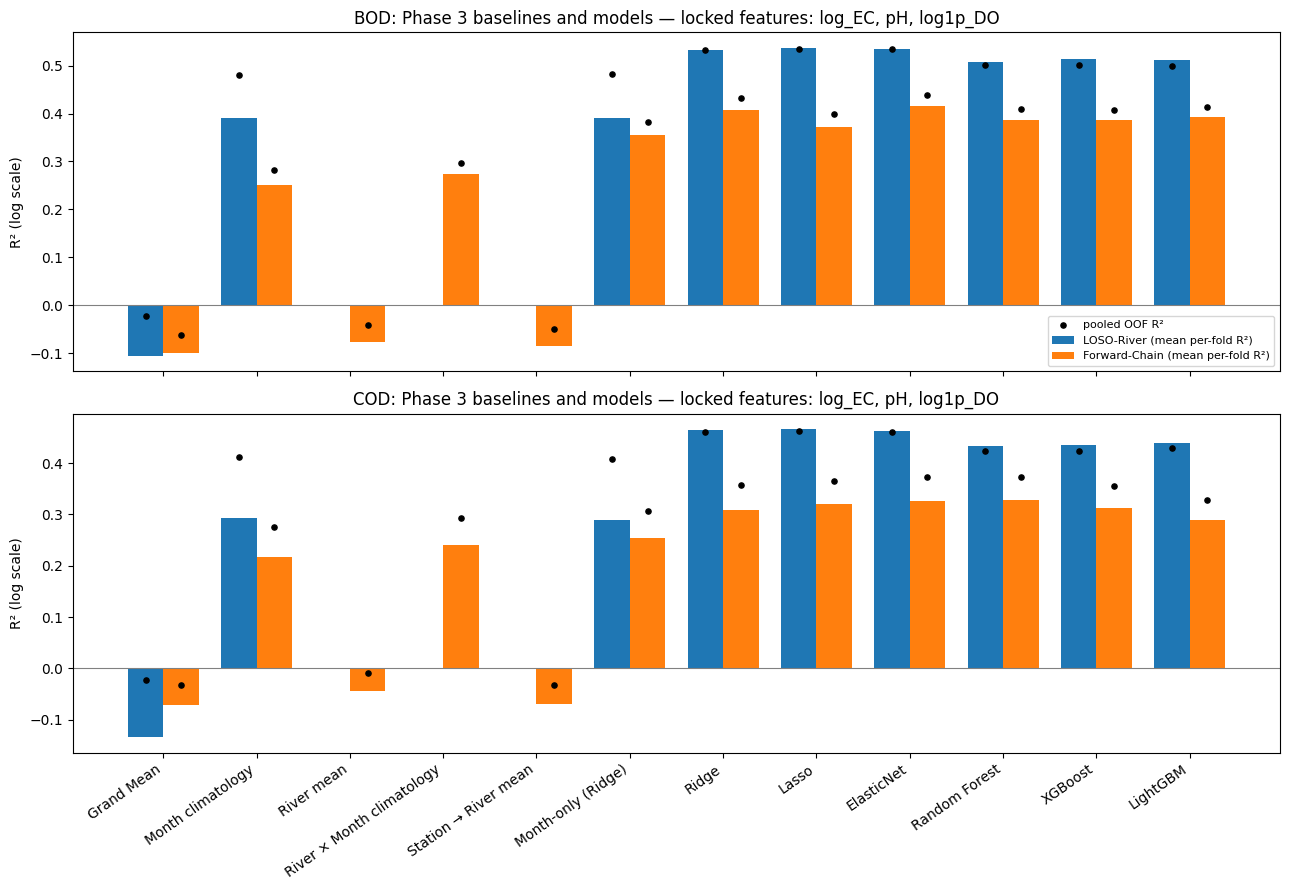

In [19]:
# Figure 1 — model comparison (positions fixed by model name)
plot_df = comparison.copy()
plot_df["plot_model"] = np.where(plot_df["family"].eq("Temporal benchmark (Ridge)"),
                                 plot_df["model"] + " (Ridge)", plot_df["model"])
models_order = ["Grand Mean", "Month climatology", "River mean", "River × Month climatology",
                "Station → River mean", "Month-only (Ridge)"]
if LOCKED_SPEC != "Chemistry-only":
    models_order.append("Chemistry-only (Ridge)")
models_order += ["Ridge", "Lasso", "ElasticNet", "Random Forest", "XGBoost", "LightGBM"]
plot_df = plot_df[plot_df["plot_model"].isin(models_order)]

fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
width = 0.38
placed = []          # (x position, model) for every bar drawn
for ax, target_tag in zip(axes, ["BOD", "COD"]):
    for k, (protocol, offset) in enumerate([("LOSO-River", -width / 2), ("Forward-Chain", width / 2)]):
        sub = plot_df[(plot_df["target"] == target_tag) & (plot_df["protocol"] == protocol)]
        x = np.array([models_order.index(m) for m in sub["plot_model"]], dtype=float)
        ax.bar(x + offset, sub["R2_log_mean"], width=width, label=f"{protocol} (mean per-fold R²)")
        placed += list(zip(x + offset, sub["plot_model"]))
        ax.scatter(x + offset, sub["R2_log_pooled"], color="black", s=14, zorder=3,
                   label="pooled OOF R²" if k == 0 else None)
    ax.axhline(0, linewidth=0.8, color="grey")
    ax.set_ylabel("R² (log scale)")
    ax.set_title(f"{target_tag}: Phase 3 baselines and models — locked features: {', '.join(MODEL_FEATURES)}")
axes[-1].set_xticks(np.arange(len(models_order)))
axes[-1].set_xticklabels(models_order, rotation=35, ha="right")
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase3_primary_r2_comparison_bod_cod.png", dpi=200, bbox_inches="tight")
plt.show()

# Check: every bar must sit above the tick label of its own model.
tick_labels = [t.get_text() for t in axes[-1].get_xticklabels()]
mislabelled = [(m, tick_labels[int(round(xp))]) for xp, m in placed if tick_labels[int(round(xp))] != m]
assert not mislabelled, f"Bars drawn above the wrong label: {mislabelled}"

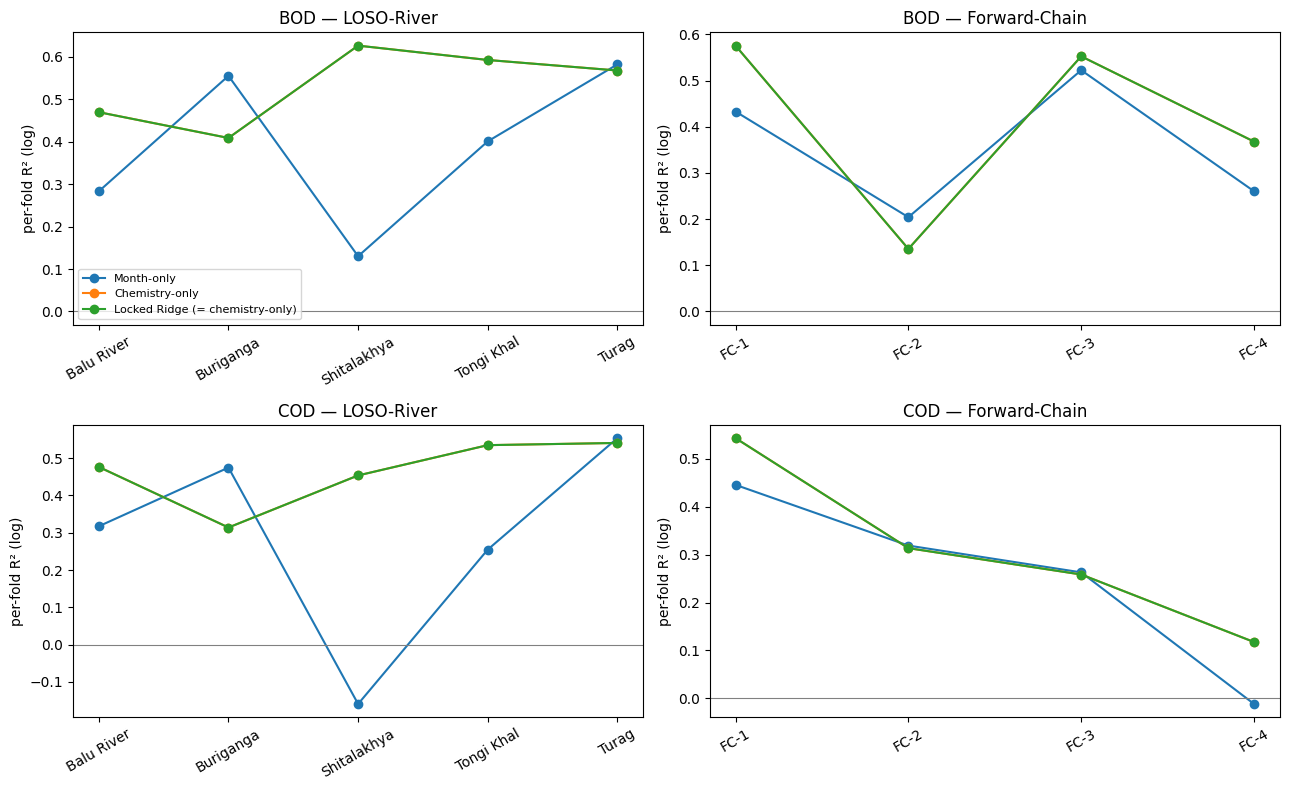

In [20]:
# Figure 2 — per-fold R² where the calendar and the chemistry disagree
series = [("Month-only", "Temporal benchmark (Ridge)", "Month-only"),
          ("Chemistry-only", "Temporal benchmark (Ridge)", "Chemistry-only"),
          (f"Locked: {LOCKED_SPEC}", "Linear", "Ridge")]
if LOCKED_SPEC == "Chemistry-only":
    series = series[:2] + [("Locked Ridge (= chemistry-only)", "Linear", "Ridge")]

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, target_tag in enumerate(["BOD", "COD"]):
    for j, protocol in enumerate(["LOSO-River", "Forward-Chain"]):
        ax = axes[i, j]
        for label, fam, mod in series:
            f = find_run(target_tag, fam, mod, protocol)["fold_df"]
            ax.plot(f["fold"].astype(str), f["R2_log"], marker="o", label=label)
        ax.axhline(0, linewidth=0.8, color="grey")
        ax.set_title(f"{target_tag} — {protocol}")
        ax.set_ylabel("per-fold R² (log)")
        ax.tick_params(axis="x", rotation=30)
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "phase3_per_fold_calendar_vs_chemistry.png", dpi=200, bbox_inches="tight")
plt.show()

# 3.8 Reproducibility and manuscript hand-off

`phase3_manifest.json` records the lock, population, grids, package versions, verification results and every file written. Files named `phase3_*` in `results/` that this run did not write are listed at the end. They come from an earlier run and should not be cited.

In [21]:
phase3_manifest = {
    "phase": "Phase 3",
    "locked_dataset": LOCKED_DATASET,
    "n_rows": len(df),
    "locked_features": MODEL_FEATURES,
    "locked_spec": LOCKED_SPEC,
    "locked_pca_block": PCA_BLOCK,
    "config_PRIMARY_FEATURES": list(PRIMARY_FEATURES),
    "phase2_selected_temporal": p2.get("selected_temporal_representation"),
    "targets": TARGETS,
    "bod_threshold_mgL": PRIMARY_THRESHOLD,
    "primary_metric": "unweighted mean of per-fold R2 (log1p scale)",
    "fold_sizes": {k: [len(te) for _, te, _ in v] for k, v in ALL_FOLDS.items() if k != "random_8020"},
    "fold_verification": fold_verification,
    "grids": {k: {p: [None if v is None else v for v in vals] for p, vals in g.items()}
              for k, g in MODEL_GRIDS.items()},
    "package_versions": PACKAGE_VERSIONS,
    "secondary_status": secondary_status,
    "cross_river_flagged_rows": int(flags.sum()),
    "outputs": sorted(set(OUTPUTS)),
    "figures": ["phase3_primary_r2_comparison_bod_cod.png", "phase3_per_fold_calendar_vs_chemistry.png"],
}
path = out_path("phase3_manifest.json")
from src.provenance import provenance   # code + data hashes, environment
phase3_manifest["provenance"] = provenance()
path.write_text(json.dumps(phase3_manifest, indent=2, default=str))
print(f"Manifest saved to: {rel(path)}")

stale = sorted(p.name for p in RESULTS_DIR.glob("phase3_*") if p.name not in set(OUTPUTS))
if stale:
    print(f"\n{len(stale)} phase3_* files in results/ were NOT written by this run (from an earlier run):")
    for s in stale:
        print("  ", s)

Manifest saved to: results/phase3_manifest.json
